In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:
# PERSIAPAN: Menentukan folder gambar praktikum

import os

FOLDER_GAMBAR = '/content/drive/MyDrive/PCVK/Gambar'

print("Folder gambar:", FOLDER_GAMBAR)
print("Folder tersedia:", os.path.exists(FOLDER_GAMBAR))

if os.path.exists(FOLDER_GAMBAR):
    print("\nDaftar file:")
    for nama in sorted(os.listdir(FOLDER_GAMBAR)):
        print("-", nama)

Folder gambar: /content/drive/MyDrive/PCVK/Gambar
Folder tersedia: True

Daftar file:
- .ipynb_checkpoints
- KTP.jpg
- bola.jpg
- buah.jpg
- couple.jpg
- crayfish.png
- foto_aktivitas.jpeg
- gedung.jpg
- house.jpg
- house_night.jpg
- ktm_lama.jpg
- messi_neymar.jpg


In [20]:
# PERSIAPAN: Instalasi library untuk praktikum P7

!pip -q install opencv-python-headless scikit-image pytesseract pandas

In [21]:
# PERSIAPAN: Import library

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pytesseract

from skimage import data, segmentation
from google.colab.patches import cv2_imshow

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Persiapan library selesai.")

OpenCV: 5.0.0
NumPy: 2.1.3
Persiapan library selesai.


In [23]:
# FUNGSI: Menampilkan beberapa citra secara berdampingan

def tampilkan_citra(gambar_list, judul_list, figsize=(16, 5)):
    plt.figure(figsize=figsize)

    for i, (gambar, judul) in enumerate(
        zip(gambar_list, judul_list), start=1
    ):
        plt.subplot(1, len(gambar_list), i)

        if gambar.ndim == 2:
            plt.imshow(gambar, cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(gambar, cv2.COLOR_BGR2RGB))

        plt.title(judul)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

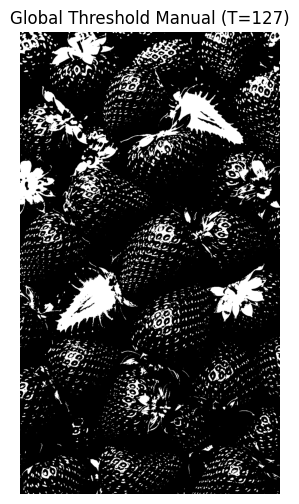

In [8]:
global_thresh = np.where(gray > 127, 255, 0).astype(np.uint8)

plt.figure(figsize=(6, 6))
plt.imshow(global_thresh, cmap='gray')
plt.title('Global Threshold Manual (T=127)')
plt.axis('off')
plt.show()

Dimensi citra berwarna: (1618, 1000, 3)
Dimensi citra grayscale: (1618, 1000)


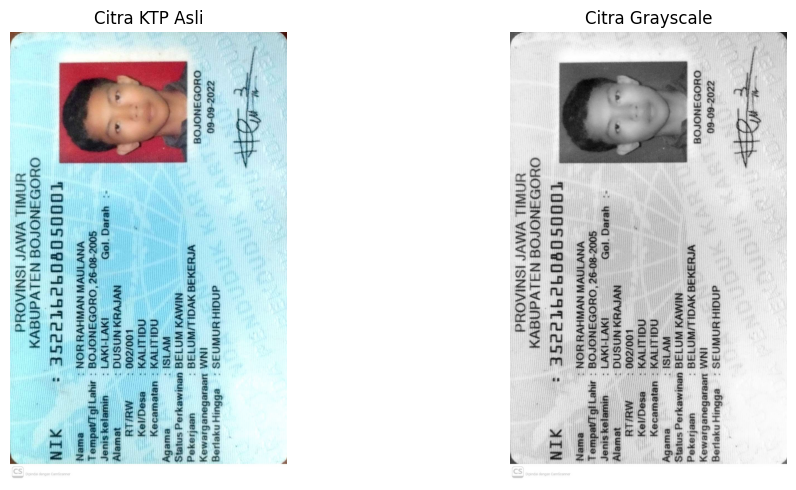

In [24]:
# PERCOBAAN 1: Menampilkan citra KTP asli dan grayscale

print("Dimensi citra berwarna:", img_ktp.shape)
print("Dimensi citra grayscale:", gray_ktp.shape)

tampilkan_citra(
    [img_ktp, gray_ktp],
    ['Citra KTP Asli', 'Citra Grayscale'],
    figsize=(12, 5)
)

Citra yang digunakan: KTP.jpg (alternatif)
Dimensi: (1618, 1000)
Intensitas minimum: 3
Intensitas maksimum: 255


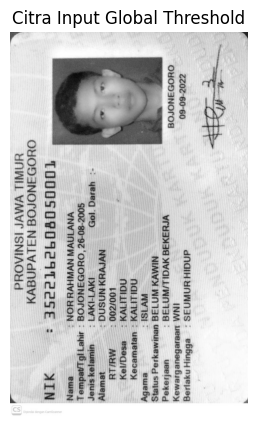

In [25]:
# PERCOBAAN 2: Menyiapkan citra untuk Global Threshold

path_gradient = os.path.join(FOLDER_GAMBAR, 'gradient.jpg')

if os.path.exists(path_gradient):
    img_global = cv2.imread(path_gradient, cv2.IMREAD_GRAYSCALE)
    nama_global = 'gradient.jpg'
else:
    img_global = gray_ktp.copy()
    nama_global = 'KTP.jpg (alternatif)'

print("Citra yang digunakan:", nama_global)
print("Dimensi:", img_global.shape)
print("Intensitas minimum:", img_global.min())
print("Intensitas maksimum:", img_global.max())

plt.figure(figsize=(7, 5))
plt.imshow(img_global, cmap='gray', vmin=0, vmax=255)
plt.title("Citra Input Global Threshold")
plt.axis('off')
plt.show()

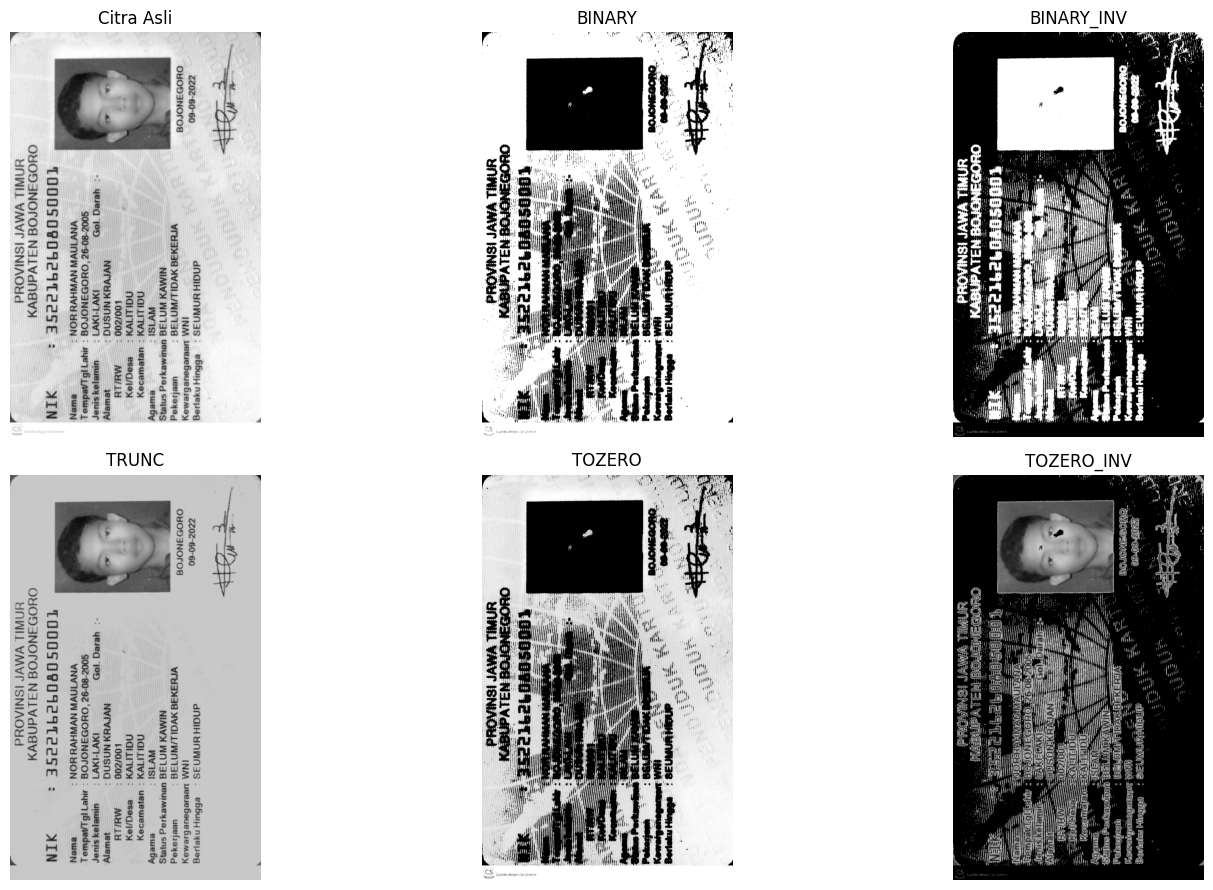

In [26]:
# PERCOBAAN 3: Implementasi lima Global Threshold secara manual

threshold = 200
maksimum = 255

# 1. BINARY
binary = np.where(
    img_global > threshold, maksimum, 0
)

# 2. BINARY_INV
binary_inv = np.where(
    img_global > threshold, 0, maksimum
)

# 3. TRUNC
trunc = np.where(
    img_global > threshold, threshold, img_global
)

# 4. TOZERO
tozero = np.where(
    img_global > threshold, img_global, 0
)

# 5. TOZERO_INV
tozero_inv = np.where(
    img_global > threshold, 0, img_global
)

hasil_global = [
    img_global,
    binary.astype(np.uint8),
    binary_inv.astype(np.uint8),
    trunc.astype(np.uint8),
    tozero.astype(np.uint8),
    tozero_inv.astype(np.uint8)
]

judul_global = [
    'Citra Asli',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]

plt.figure(figsize=(16, 9))

for i, (gambar, judul) in enumerate(
    zip(hasil_global, judul_global), start=1
):
    plt.subplot(2, 3, i)
    plt.imshow(gambar, cmap='gray', vmin=0, vmax=255)
    plt.title(judul)
    plt.axis('off')

plt.tight_layout()
plt.show()

Dimensi Sudoku: (246, 205)


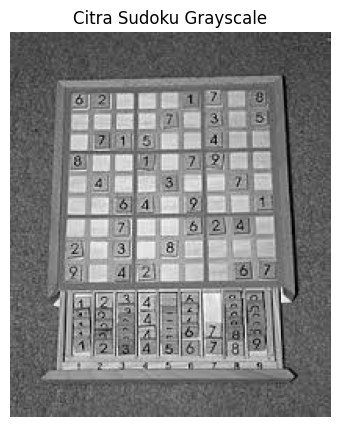

In [28]:
# PERCOBAAN 4.1: Membaca citra Sudoku

path_sudoku = os.path.join(
    FOLDER_GAMBAR,
    'sudoku-original.jpg'
)

img_sudoku = cv2.imread(
    path_sudoku,
    cv2.IMREAD_GRAYSCALE
)

if img_sudoku is None:
    raise FileNotFoundError(
        "Tambahkan sudoku-original.jpg ke folder PCVK/Gambar di Drive."
    )

print("Dimensi Sudoku:", img_sudoku.shape)

plt.figure(figsize=(7, 5))
plt.imshow(img_sudoku, cmap='gray')
plt.title("Citra Sudoku Grayscale")
plt.axis('off')
plt.show()

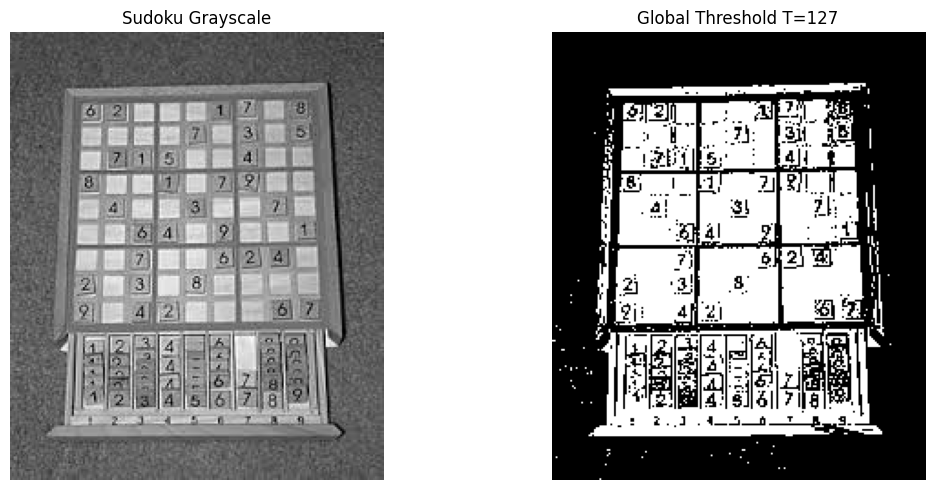

In [29]:
# PERCOBAAN 4.2: Global Threshold manual pada Sudoku, T=127

global_sudoku = np.where(
    img_sudoku > 127,
    255,
    0
).astype(np.uint8)

tampilkan_citra(
    [img_sudoku, global_sudoku],
    ['Sudoku Grayscale', 'Global Threshold T=127'],
    figsize=(12, 5)
)

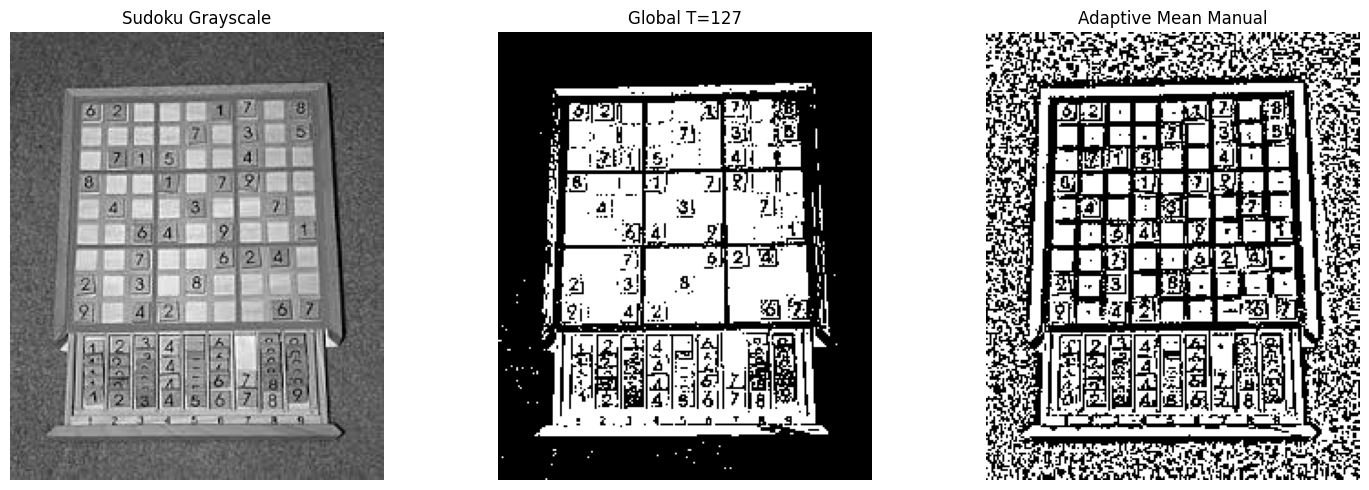

In [30]:
# PERCOBAAN 4.3: Implementasi Adaptive Mean secara manual

def adaptive_mean_manual(image, block_size=11, C=2):
    image = image.astype(np.float64)

    h, w = image.shape
    pad = block_size // 2

    padded = np.pad(
        image,
        ((pad, pad), (pad, pad)),
        mode='reflect'
    )

    # Integral image untuk menghitung rata-rata jendela
    integral = np.pad(
        padded.cumsum(axis=0).cumsum(axis=1),
        ((1, 0), (1, 0)),
        mode='constant'
    )

    local_sum = (
        integral[block_size:, block_size:]
        - integral[:-block_size, block_size:]
        - integral[block_size:, :-block_size]
        + integral[:-block_size, :-block_size]
    )

    local_mean = local_sum / (block_size * block_size)
    local_threshold = local_mean - C

    result = np.where(image > local_threshold, 255, 0)

    return result.astype(np.uint8)


adaptive_mean = adaptive_mean_manual(
    img_sudoku,
    block_size=11,
    C=2
)

tampilkan_citra(
    [img_sudoku, global_sudoku, adaptive_mean],
    [
        'Sudoku Grayscale',
        'Global T=127',
        'Adaptive Mean Manual'
    ],
    figsize=(15, 5)
)

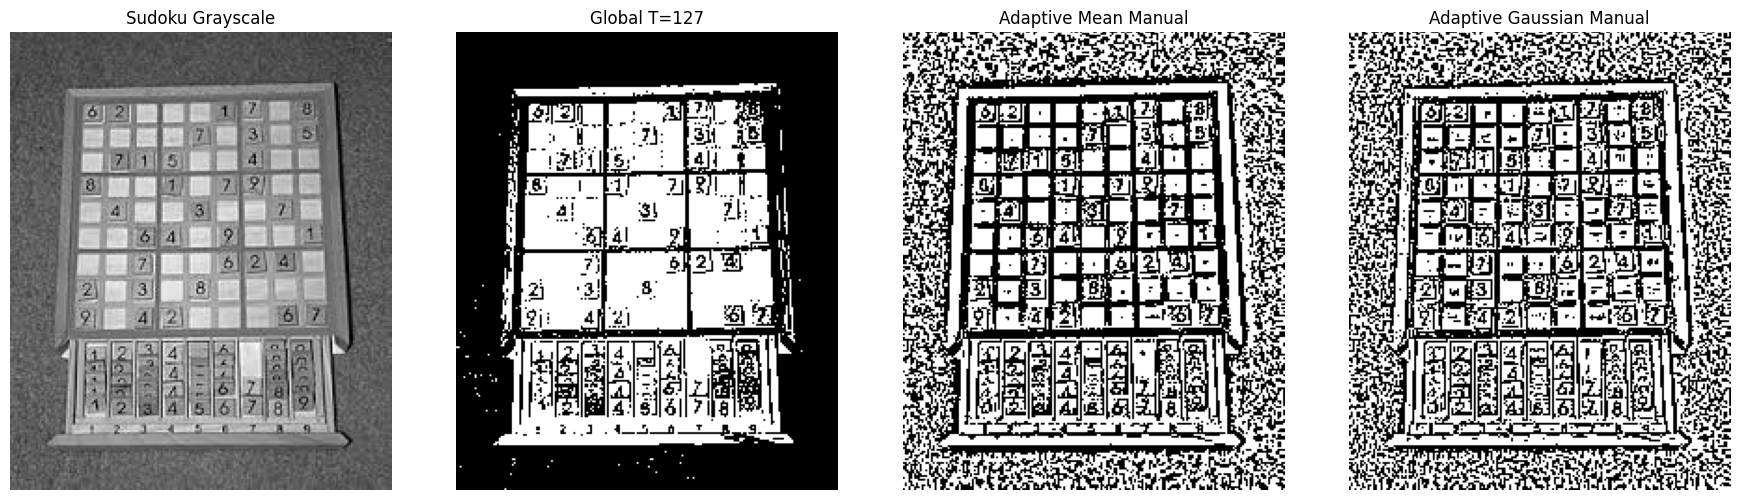

In [31]:
# PERCOBAAN 4.4: Implementasi Adaptive Gaussian secara manual

def gaussian_kernel_manual(size=11, sigma=2):
    radius = size // 2

    axis = np.arange(
        -radius,
        radius + 1,
        dtype=np.float64
    )

    xx, yy = np.meshgrid(axis, axis)

    kernel = np.exp(
        -(xx**2 + yy**2) / (2 * sigma**2)
    )

    kernel /= kernel.sum()

    return kernel


def adaptive_gaussian_manual(
    image,
    block_size=11,
    C=2,
    sigma=2
):
    image = image.astype(np.float64)

    h, w = image.shape
    pad = block_size // 2

    padded = np.pad(
        image,
        ((pad, pad), (pad, pad)),
        mode='reflect'
    )

    kernel = gaussian_kernel_manual(
        size=block_size,
        sigma=sigma
    )

    local_mean = np.empty(
        (h, w),
        dtype=np.float64
    )

    # Proses satu baris keluaran pada setiap iterasi
    for row in range(h):

        # Potongan ini menghasilkan tepat satu baris jendela keluaran
        row_windows = np.lib.stride_tricks.sliding_window_view(
            padded[row:row + block_size, :],
            (block_size, block_size)
        )

        # Bentuk row_windows: (1, w, block_size, block_size)
        # Ambil baris pertama, bukan row_windows[row]
        local_mean[row] = np.einsum(
            'ijk,jk->i',
            row_windows[0],
            kernel
        )

    local_threshold = local_mean - C

    result = np.where(
        image > local_threshold,
        255,
        0
    )

    return result.astype(np.uint8)


adaptive_gaussian = adaptive_gaussian_manual(
    img_sudoku,
    block_size=11,
    C=2,
    sigma=2
)

tampilkan_citra(
    [
        img_sudoku,
        global_sudoku,
        adaptive_mean,
        adaptive_gaussian
    ],
    [
        'Sudoku Grayscale',
        'Global T=127',
        'Adaptive Mean Manual',
        'Adaptive Gaussian Manual'
    ],
    figsize=(18, 5)
)

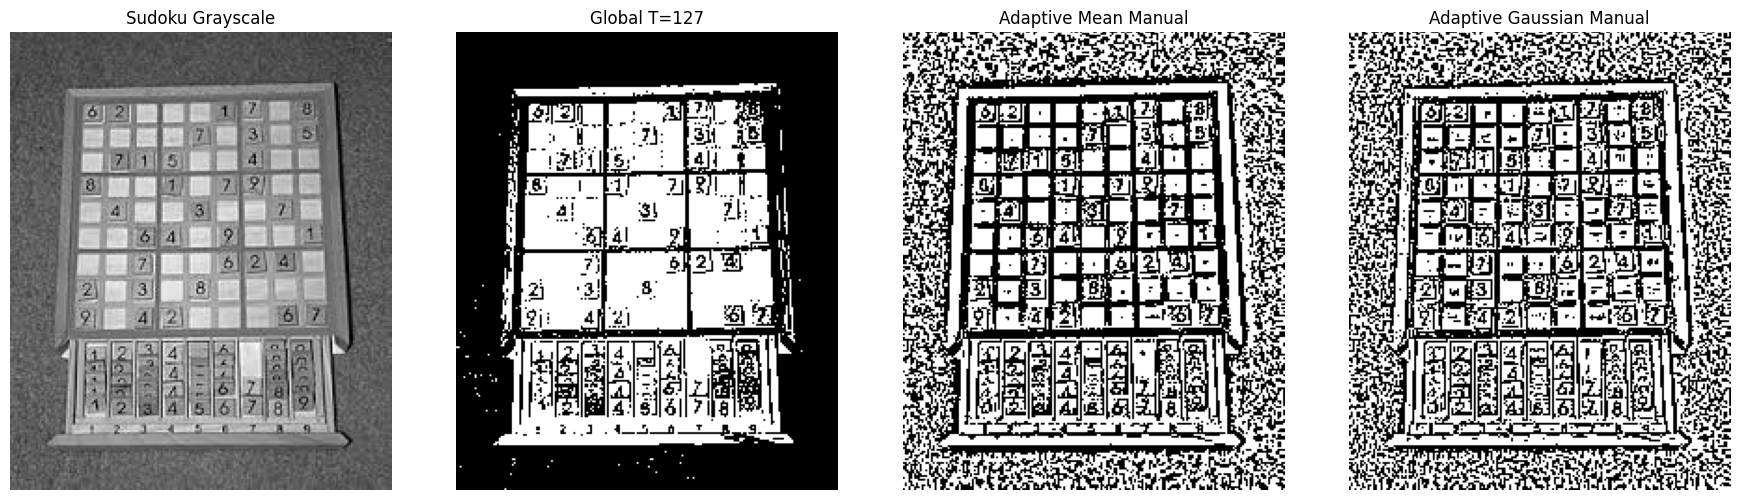

In [32]:
# PERCOBAAN 4.4: Implementasi Adaptive Gaussian secara manual

def gaussian_kernel_manual(size=11, sigma=2):
    radius = size // 2

    axis = np.arange(
        -radius,
        radius + 1,
        dtype=np.float64
    )

    xx, yy = np.meshgrid(axis, axis)

    kernel = np.exp(
        -(xx**2 + yy**2) / (2 * sigma**2)
    )

    kernel /= kernel.sum()

    return kernel


def adaptive_gaussian_manual(
    image,
    block_size=11,
    C=2,
    sigma=2
):
    image = image.astype(np.float64)

    h, w = image.shape
    pad = block_size // 2

    padded = np.pad(
        image,
        ((pad, pad), (pad, pad)),
        mode='reflect'
    )

    kernel = gaussian_kernel_manual(
        size=block_size,
        sigma=sigma
    )

    local_mean = np.empty(
        (h, w),
        dtype=np.float64
    )

    # Proses satu baris keluaran pada setiap iterasi
    for row in range(h):

        # Potongan ini menghasilkan tepat satu baris jendela keluaran
        row_windows = np.lib.stride_tricks.sliding_window_view(
            padded[row:row + block_size, :],
            (block_size, block_size)
        )

        # Bentuk row_windows: (1, w, block_size, block_size)
        # Ambil baris pertama, bukan row_windows[row]
        local_mean[row] = np.einsum(
            'ijk,jk->i',
            row_windows[0],
            kernel
        )

    local_threshold = local_mean - C

    result = np.where(
        image > local_threshold,
        255,
        0
    )

    return result.astype(np.uint8)


adaptive_gaussian = adaptive_gaussian_manual(
    img_sudoku,
    block_size=11,
    C=2,
    sigma=2
)

tampilkan_citra(
    [
        img_sudoku,
        global_sudoku,
        adaptive_mean,
        adaptive_gaussian
    ],
    [
        'Sudoku Grayscale',
        'Global T=127',
        'Adaptive Mean Manual',
        'Adaptive Gaussian Manual'
    ],
    figsize=(18, 5)
)

Dimensi Lena: (512, 512)
Intensitas minimum: 95
Intensitas maksimum: 159


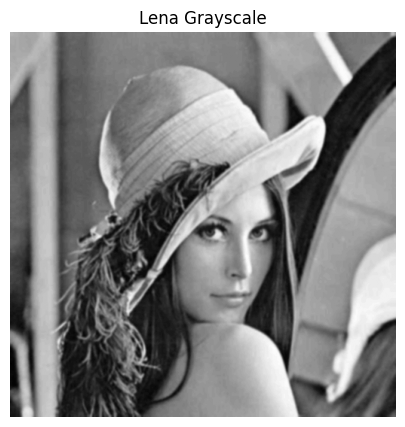

In [34]:
# PERCOBAAN 5.1: Membaca gambar Lena low contrast

path_lena = os.path.join(
    FOLDER_GAMBAR,
    'lena_gs_lc2.jpg'
)

lena = cv2.imread(path_lena, cv2.IMREAD_GRAYSCALE)

if lena is None:
    raise FileNotFoundError(
        "Tambahkan lena_gs_lc2.jpg ke folder PCVK/Gambar di Drive."
    )

lena_blur = cv2.GaussianBlur(lena, (5, 5), 0)

print("Dimensi Lena:", lena.shape)
print("Intensitas minimum:", lena.min())
print("Intensitas maksimum:", lena.max())

plt.figure(figsize=(7, 5))
plt.imshow(lena_blur, cmap='gray')
plt.title("Lena Grayscale")
plt.axis('off')
plt.show()

In [35]:
# PERCOBAAN 5.2: Otsu Thresholding tanpa fungsi threshold library

def otsu_manual(gray):
    gray = gray.astype(np.uint8)

    histogram = np.bincount(
        gray.ravel(),
        minlength=256
    ).astype(np.float64)

    intensitas = np.arange(256, dtype=np.float64)

    total_piksel = gray.size
    total_intensitas = np.sum(histogram * intensitas)

    bobot_latar = np.cumsum(histogram)
    jumlah_intensitas_latar = np.cumsum(
        histogram * intensitas
    )

    bobot_objek = total_piksel - bobot_latar
    jumlah_intensitas_objek = (
        total_intensitas - jumlah_intensitas_latar
    )

    mean_latar = np.divide(
        jumlah_intensitas_latar,
        bobot_latar,
        out=np.zeros(256),
        where=bobot_latar > 0
    )

    mean_objek = np.divide(
        jumlah_intensitas_objek,
        bobot_objek,
        out=np.zeros(256),
        where=bobot_objek > 0
    )

    varians_antar_kelas = (
        bobot_latar * bobot_objek
        * (mean_latar - mean_objek) ** 2
    )

    # Abaikan ambang yang menghasilkan kelas kosong
    valid = (bobot_latar > 0) & (bobot_objek > 0)
    varians_antar_kelas[~valid] = -1

    threshold = int(np.argmax(varians_antar_kelas))

    hasil = np.where(
        gray > threshold,
        255,
        0
    ).astype(np.uint8)

    return hasil, threshold


otsu_lena, nilai_otsu_lena = otsu_manual(lena_blur)

print("Nilai threshold Otsu manual:", nilai_otsu_lena)

Nilai threshold Otsu manual: 124


Threshold manual Otsu: 124
Threshold Otsu OpenCV: 124.0


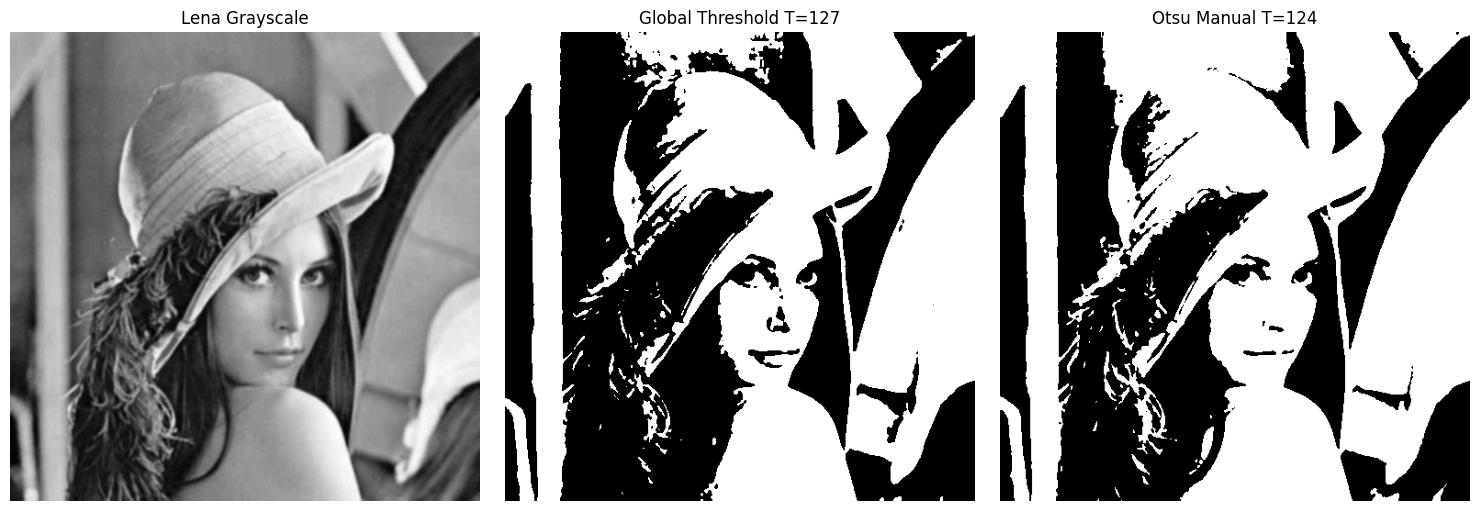

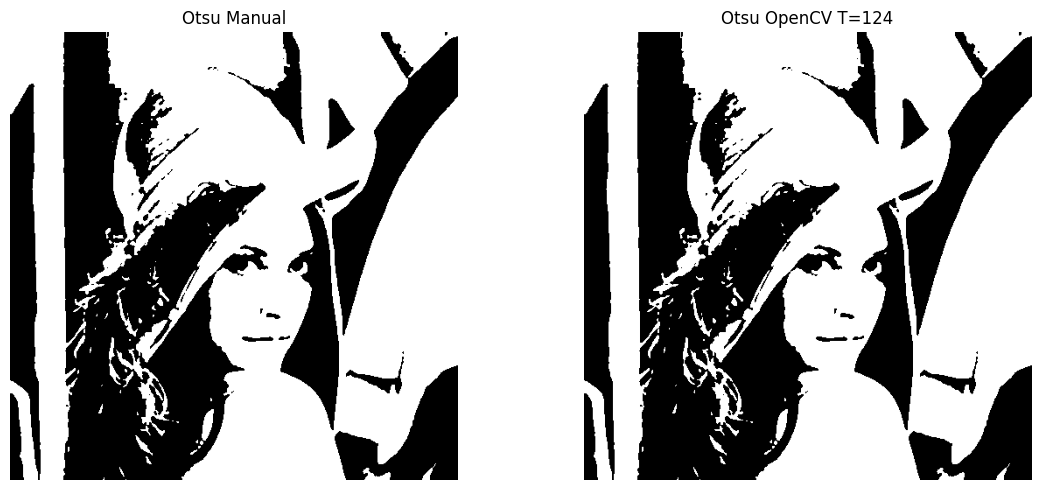

In [36]:
# PERCOBAAN 5.3: Perbandingan Global Threshold dan Otsu OpenCV

global_lena = np.where(
    lena_blur > 127,
    255,
    0
).astype(np.uint8)

nilai_otsu_cv, otsu_lena_cv = cv2.threshold(
    lena_blur,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Threshold manual Otsu:", nilai_otsu_lena)
print("Threshold Otsu OpenCV:", nilai_otsu_cv)

tampilkan_citra(
    [
        lena_blur,
        global_lena,
        otsu_lena
    ],
    [
        'Lena Grayscale',
        'Global Threshold T=127',
        f'Otsu Manual T={nilai_otsu_lena}'
    ],
    figsize=(15, 5)
)

tampilkan_citra(
    [otsu_lena, otsu_lena_cv],
    ['Otsu Manual', f'Otsu OpenCV T={nilai_otsu_cv:.0f}'],
    figsize=(12, 5)
)

Nilai threshold Otsu KTP: 157


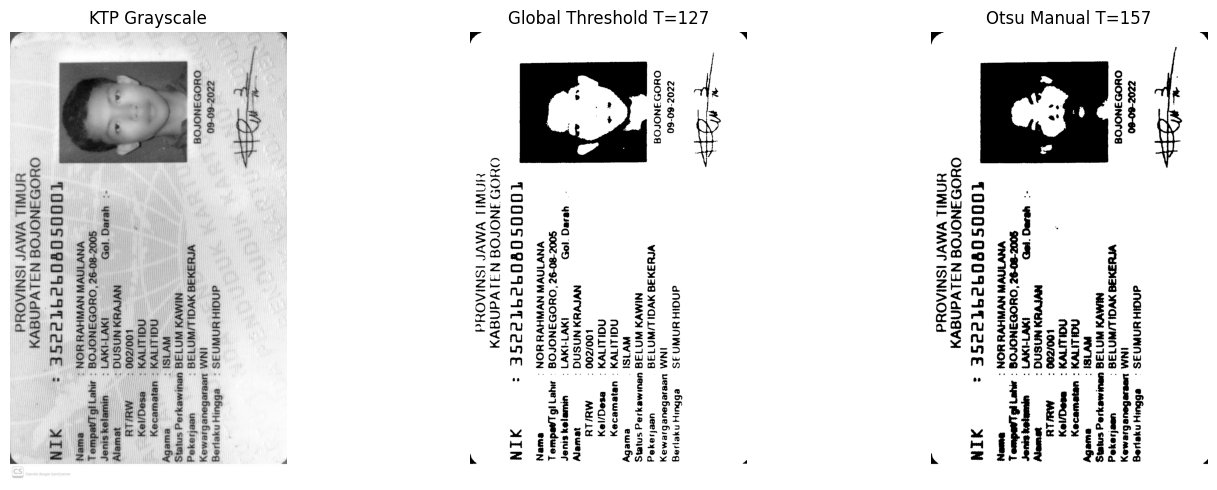

In [37]:
# PERCOBAAN 5.4: Perbandingan Global Threshold dan Otsu pada KTP sendiri

ktp_blur = cv2.GaussianBlur(
    gray_ktp,
    (5, 5),
    0
)

ktp_global_127 = np.where(
    ktp_blur > 127,
    255,
    0
).astype(np.uint8)

ktp_otsu_manual, nilai_otsu_ktp = otsu_manual(ktp_blur)

print("Nilai threshold Otsu KTP:", nilai_otsu_ktp)

tampilkan_citra(
    [
        gray_ktp,
        ktp_global_127,
        ktp_otsu_manual
    ],
    [
        'KTP Grayscale',
        'Global Threshold T=127',
        f'Otsu Manual T={nilai_otsu_ktp}'
    ],
    figsize=(15, 5)
)

Mengapa hasil Binary Thresholding pada Lena menjadi hitam semua? Jelaskan berdasarkan histogram dan berapa nilai ambang agar gambar Lena masih terlihat.

Citra Lena yang digunakan pada modul merupakan citra low contrast, dengan intensitas piksel sekitar 85–108. Jika nilai threshold ditetapkan sebesar 127, seluruh piksel memiliki intensitas di bawah atau sama dengan ambang tersebut. Pada Binary Threshold, piksel yang nilainya tidak lebih besar dari ambang akan diubah menjadi 0 sehingga citra menjadi hitam seluruhnya.
Pada histogram, kondisi tersebut terlihat karena distribusi intensitas berada di bawah nilai 127. Agar gambar masih terlihat, nilai threshold perlu diturunkan hingga berada di bawah sebagian rentang intensitas gambar. Sebagai percobaan awal, gunakan T=90 atau T=95, lalu amati hasilnya. Nilai terbaik bergantung pada histogram dan hasil gambar yang digunakan.

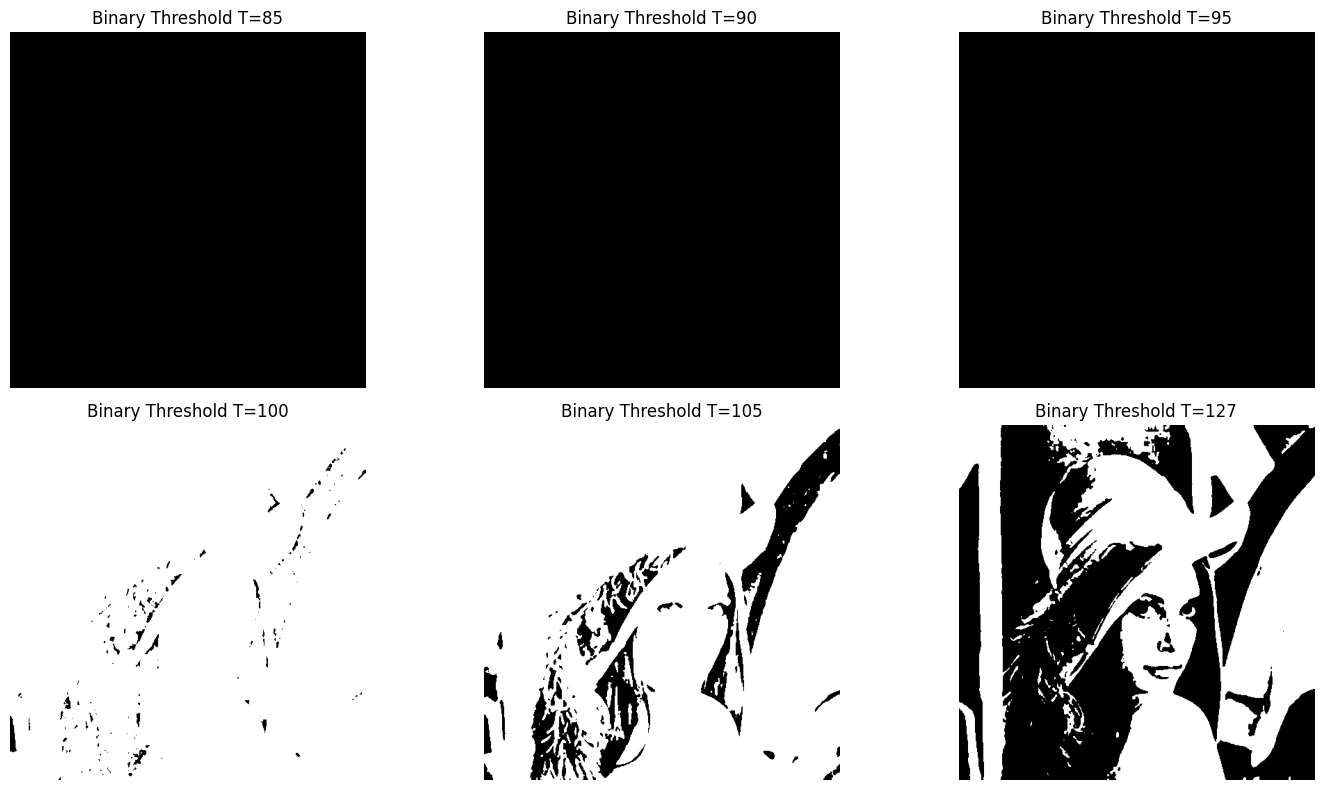

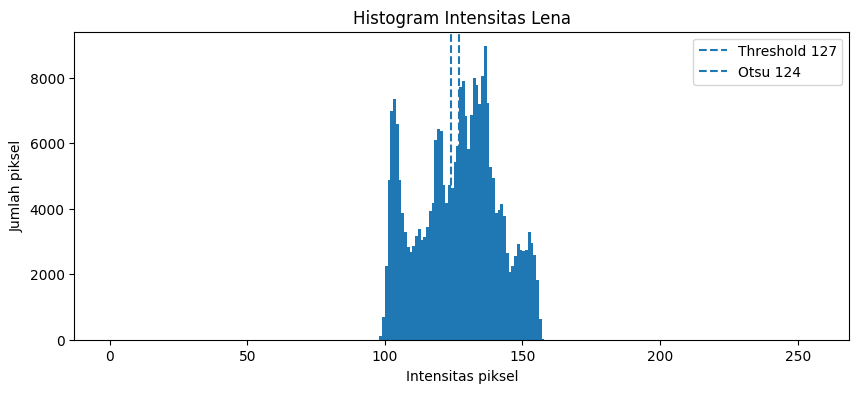

In [39]:
# PERCOBAAN 5.5: Menguji beberapa threshold pada Lena

threshold_uji = [85, 90, 95, 100, 105, 127]

plt.figure(figsize=(15, 8))

for i, t in enumerate(threshold_uji, start=1):
    hasil = np.where(lena_blur > t, 255, 0).astype(np.uint8)

    plt.subplot(2, 3, i)
    plt.imshow(hasil, cmap='gray')
    plt.title(f'Binary Threshold T={t}')
    plt.axis('off')

plt.tight_layout()
plt.show()

# Histogram intensitas
plt.figure(figsize=(10, 4))
plt.hist(lena_blur.ravel(), bins=256, range=(0, 256))
plt.axvline(127, linestyle='--', label='Threshold 127')
plt.axvline(nilai_otsu_lena, linestyle='--',
            label=f'Otsu {nilai_otsu_lena}')
plt.title('Histogram Intensitas Lena')
plt.xlabel('Intensitas piksel')
plt.ylabel('Jumlah piksel')
plt.legend()
plt.show()

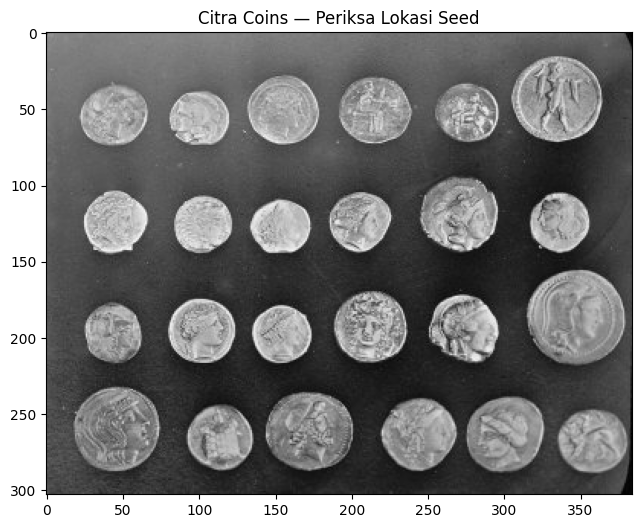

Dimensi citra coins: (303, 384)


In [40]:
# PERCOBAAN 6.1: Memuat data.coins dan menentukan tiga seed

coins = data.coins()

plt.figure(figsize=(8, 6))
plt.imshow(coins, cmap='gray')
plt.title("Citra Coins — Periksa Lokasi Seed")
plt.axis('on')
plt.show()

print("Dimensi citra coins:", coins.shape)

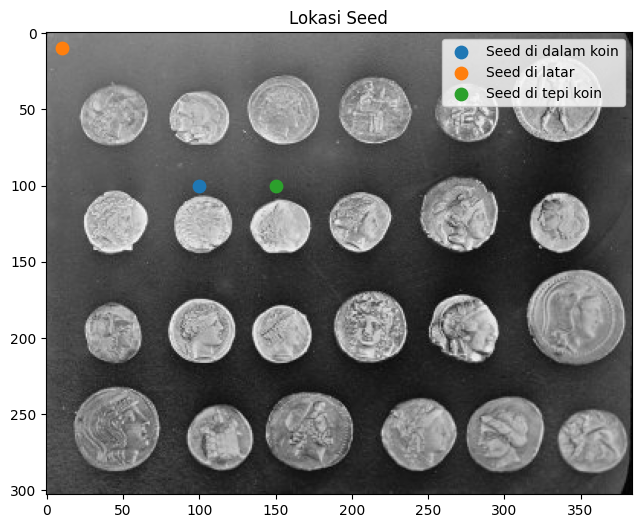

In [41]:
# PERCOBAAN 6.2: Menetapkan seed untuk koin, latar, dan tepi

seed_koin = (100, 100)
seed_latar = (10, 10)
seed_tepi = (100, 150)

seeds = {
    'Seed di dalam koin': seed_koin,
    'Seed di latar': seed_latar,
    'Seed di tepi koin': seed_tepi
}

plt.figure(figsize=(8, 6))
plt.imshow(coins, cmap='gray')

for nama, (r, c) in seeds.items():
    plt.scatter(c, r, s=80, label=nama)

plt.title("Lokasi Seed")
plt.legend()
plt.show()

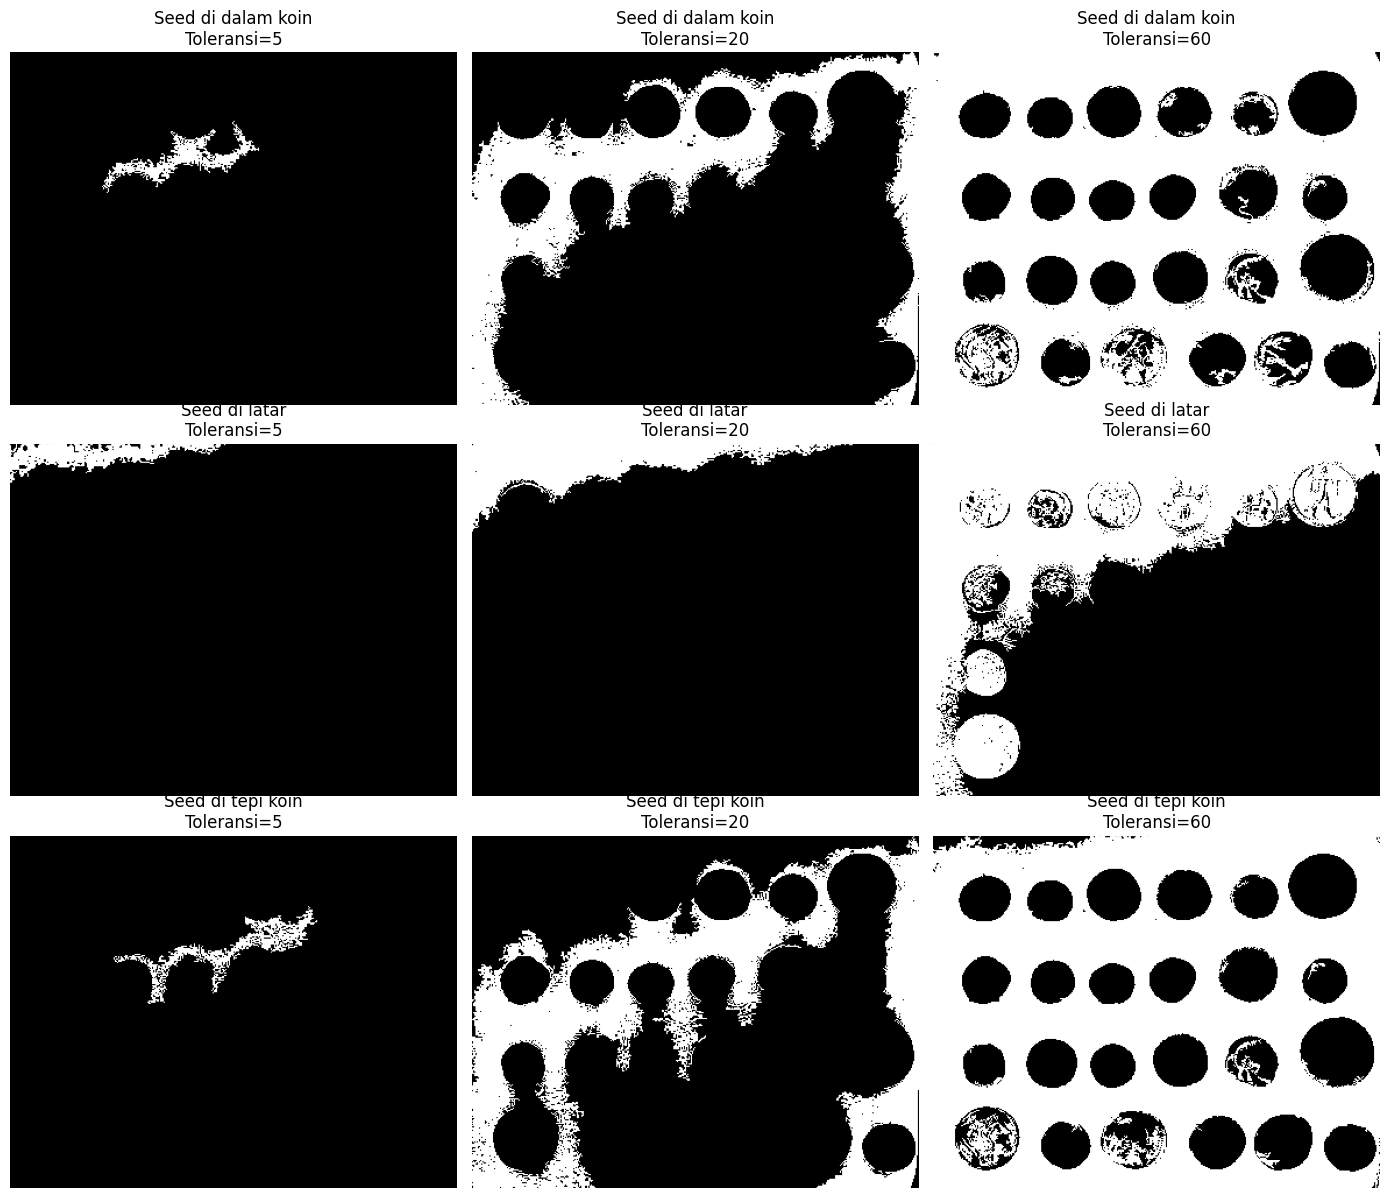

In [42]:
# PERCOBAAN 6.3: Segmentasi region dengan flood untuk T=5, 20, 60

toleransi_list = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for baris, (nama_seed, koordinat) in enumerate(seeds.items()):
    for kolom, toleransi in enumerate(toleransi_list):

        mask = segmentation.flood(
            coins,
            seed_point=koordinat,
            tolerance=toleransi
        )

        axes[baris, kolom].imshow(mask, cmap='gray')
        axes[baris, kolom].set_title(
            f'{nama_seed}\nToleransi={toleransi}'
        )
        axes[baris, kolom].axis('off')

plt.tight_layout()
plt.show()

Mengapa hasil segmentasi region berubah ketika nilai toleransi meningkat?

Jawab : Fungsi flood() menghubungkan piksel yang memenuhi toleransi intensitas terhadap piksel seed. Ketika toleransi kecil, hanya piksel dengan intensitas yang dekat dengan seed yang cenderung masuk ke region. Ketika toleransi meningkat, semakin banyak piksel dengan intensitas berbeda yang dapat diterima sehingga region dapat menjadi lebih luas dan berpotensi mencakup bagian latar atau objek lain.

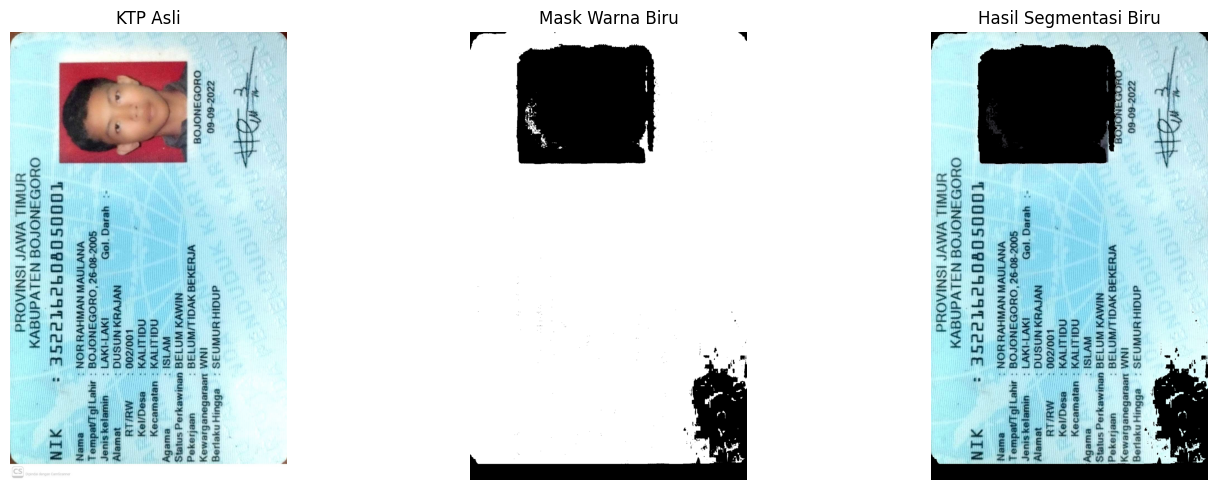

In [43]:
# PERCOBAAN 7: Segmentasi warna biru pada KTP menggunakan HSV

path_ktp_biru = os.path.join(
    FOLDER_GAMBAR,
    'KTP.jpg'
)

ktp_biru = cv2.imread(path_ktp_biru)

if ktp_biru is None:
    raise FileNotFoundError("File KTP untuk segmentasi biru tidak ditemukan.")

hsv = cv2.cvtColor(ktp_biru, cv2.COLOR_BGR2HSV)

H = hsv[:, :, 0]
S = hsv[:, :, 1]
V = hsv[:, :, 2]

mask_biru = (
    (H >= 85) &
    (H <= 130) &
    (S >= 25) &
    (V >= 40)
)

hasil_biru = np.zeros_like(ktp_biru)
hasil_biru[mask_biru] = ktp_biru[mask_biru]

mask_tampilan = (mask_biru.astype(np.uint8) * 255)

tampilkan_citra(
    [
        ktp_biru,
        cv2.cvtColor(mask_tampilan, cv2.COLOR_GRAY2BGR),
        hasil_biru
    ],
    [
        'KTP Asli',
        'Mask Warna Biru',
        'Hasil Segmentasi Biru'
    ],
    figsize=(15, 5)
)

In [44]:
# PERCOBAAN 8.1: Instalasi Tesseract OCR dan model bahasa Indonesia

!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [45]:
# PERCOBAAN 8.2: Memeriksa versi dan bahasa Tesseract

!tesseract --version
!tesseract --list-langs

tesseract 5.3.4
 leptonica-1.82.0
  libgif 5.2.1 : libjpeg 8d (libjpeg-turbo 2.1.5) : libpng 1.6.43 : libtiff 4.5.1 : zlib 1.3 : libwebp 1.3.2 : libopenjp2 2.5.0
 Found AVX2
 Found AVX
 Found FMA
 Found SSE4.1
 Found OpenMP 201511
 Found libarchive 3.7.2 zlib/1.3 liblzma/5.4.5 bz2lib/1.0.8 liblz4/1.9.4 libzstd/1.5.5
 Found libcurl/8.5.0 OpenSSL/3.0.13 zlib/1.3 brotli/1.1.0 zstd/1.5.5 libidn2/2.3.7 libpsl/0.21.2 (+libidn2/2.3.7) libssh/0.10.6/openssl/zlib nghttp2/1.59.0 librtmp/2.3 OpenLDAP/2.6.10
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
ind
osd


Ukuran citra asli: (1618, 1000)
Ukuran citra Otsu: (1618, 1000)
Ukuran citra Adaptive: (1618, 1000)


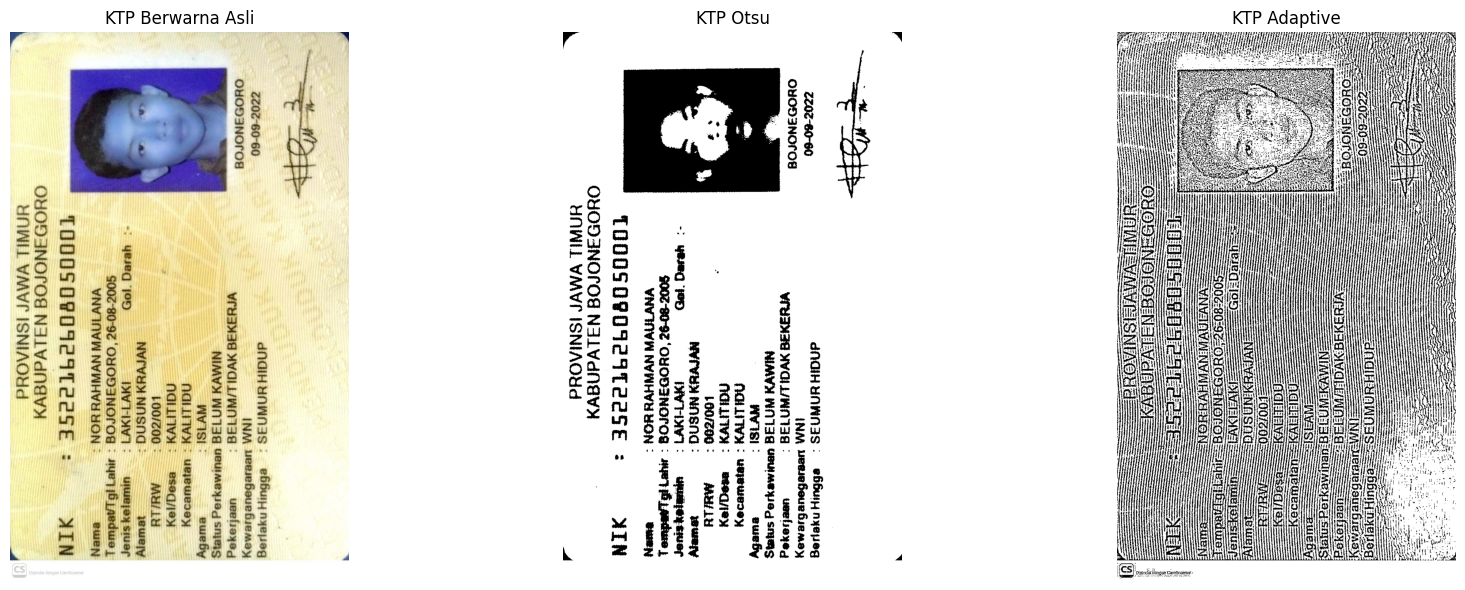

In [46]:
# PERCOBAAN 9: Membuat citra asli, Otsu, dan Adaptive untuk OCR

path_ktp_ocr = os.path.join(
    FOLDER_GAMBAR,
    'KTP.jpg'
)

ktp_ocr_bgr = cv2.imread(path_ktp_ocr)

if ktp_ocr_bgr is None:
    raise FileNotFoundError(
        "KTP.jpg tidak ditemukan di folder PCVK/Gambar."
    )

# Citra asli untuk OCR
ktp_ocr_rgb = cv2.cvtColor(
    ktp_ocr_bgr,
    cv2.COLOR_BGR2RGB
)

# Grayscale untuk proses thresholding
ktp_ocr_gray = cv2.cvtColor(
    ktp_ocr_bgr,
    cv2.COLOR_BGR2GRAY
)

# Otsu Thresholding
_, ktp_ocr_otsu = cv2.threshold(
    ktp_ocr_gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Adaptive Thresholding
ktp_ocr_adaptive = cv2.adaptiveThreshold(
    ktp_ocr_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

print("Ukuran citra asli:", ktp_ocr_rgb.shape[:2])
print("Ukuran citra Otsu:", ktp_ocr_otsu.shape)
print("Ukuran citra Adaptive:", ktp_ocr_adaptive.shape)

tampilkan_citra(
    [
        ktp_ocr_rgb,
        ktp_ocr_otsu,
        ktp_ocr_adaptive
    ],
    [
        'KTP Berwarna Asli',
        'KTP Otsu',
        'KTP Adaptive'
    ],
    figsize=(18, 6)
)

In [47]:
# PERCOBAAN 10: Membaca teks pada tiga citra menggunakan Tesseract

konfigurasi_ocr = '--oem 3 --psm 6'

teks_ocr_berwarna = pytesseract.image_to_string(
    ktp_ocr_rgb,
    lang='ind',
    config=konfigurasi_ocr
)

teks_ocr_otsu = pytesseract.image_to_string(
    ktp_ocr_otsu,
    lang='ind',
    config=konfigurasi_ocr
)

teks_ocr_adaptive = pytesseract.image_to_string(
    ktp_ocr_adaptive,
    lang='ind',
    config=konfigurasi_ocr
)

print("=" * 60)
print("OCR CITRA BERWARNA ASLI")
print("=" * 60)
print(teks_ocr_berwarna)

print("\n" + "=" * 60)
print("OCR CITRA OTSU")
print("=" * 60)
print(teks_ocr_otsu)

print("\n" + "=" * 60)
print("OCR CITRA ADAPTIVE")
print("=" * 60)
print(teks_ocr_adaptive)

OCR CITRA BERWARNA ASLI
»
Te!
& h
1
Ba:
£ AA | 1 NM Hi TM i
3 2 |.
:3 : : Mi 5 z
£ 1 Bi "3
T 1 ih
:3 EN K, MG P
5 TAN
sii
N


OCR CITRA OTSU
2.
f aj ,
ta KEMU
: Pat
ba
0
3Ga |
2G NN
s0 9 "
230 s3 :
2
— 2
NE ! 33
5& Uu 33
35 PA haBR an £
LG Hanana 232p
K: Pai
oOhalih
. a: | IE
: Bh |
Sg Haii
“ 4


OCR CITRA ADAPTIVE
NN ANA
5 Da
! Ii 2 “
1 en
25. sa —
0 AN an
m3 Use | 1 n | 1
Sa — | | |
Ka Ug “IG | 1 |
“ne " 1 .
aa na —E 1
2 Pa 2 |
|
an 2. ella 1
| | — Ta P UN n
1 1 1 2 n n ”
| Ne Tn “3



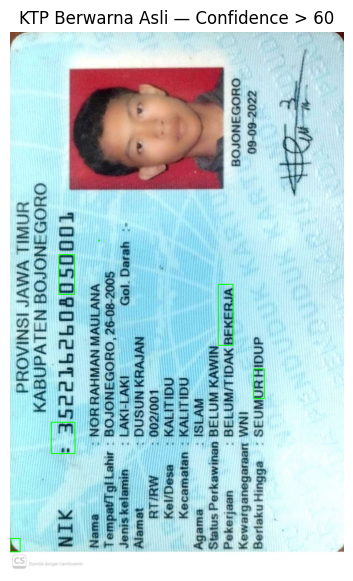

Jumlah kotak dengan confidence > 60 : 6
Rata-rata confidence: 81.26


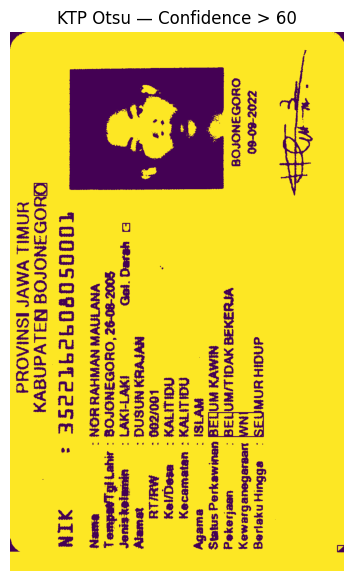

Jumlah kotak dengan confidence > 60 : 8
Rata-rata confidence: 77.95


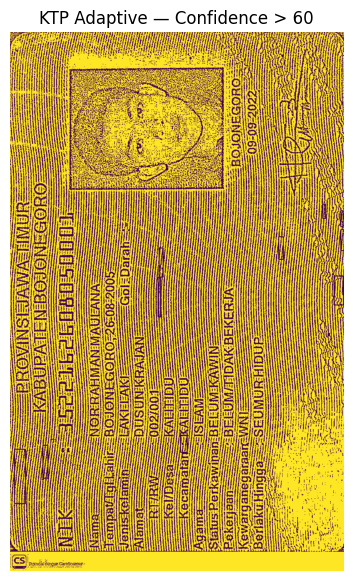

Jumlah kotak dengan confidence > 60 : 11
Rata-rata confidence: 82.99


In [48]:
# PERCOBAAN 11: Membuat kotak hijau berdasarkan confidence OCR > 60

def tampilkan_kotak_ocr(image_rgb, nama_citra, confidence_min=60):
    data_ocr = pytesseract.image_to_data(
        image_rgb,
        lang='ind',
        config=konfigurasi_ocr,
        output_type=pytesseract.Output.DATAFRAME
    )

    # Hilangkan data yang tidak valid
    data_ocr = data_ocr.dropna(subset=['text', 'conf']).copy()
    data_ocr['text'] = data_ocr['text'].astype(str).str.strip()
    data_ocr['conf'] = pd.to_numeric(
        data_ocr['conf'],
        errors='coerce'
    )

    data_valid = data_ocr[
        (data_ocr['text'] != '') &
        (data_ocr['conf'] > confidence_min)
    ]

    hasil_gambar = image_rgb.copy()

    for _, baris in data_valid.iterrows():
        x = int(baris['left'])
        y = int(baris['top'])
        w = int(baris['width'])
        h = int(baris['height'])

        cv2.rectangle(
            hasil_gambar,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    plt.figure(figsize=(12, 7))
    plt.imshow(hasil_gambar)
    plt.title(f'{nama_citra} — Confidence > {confidence_min}')
    plt.axis('off')
    plt.show()

    rata_conf = (
        data_valid['conf'].mean()
        if not data_valid.empty
        else 0.0
    )

    print("Jumlah kotak dengan confidence >", confidence_min,
          ":", len(data_valid))
    print("Rata-rata confidence:", round(rata_conf, 2))

    return data_ocr, rata_conf


data_berwarna, conf_berwarna = tampilkan_kotak_ocr(
    ktp_ocr_rgb,
    'KTP Berwarna Asli'
)

data_otsu, conf_otsu = tampilkan_kotak_ocr(
    ktp_ocr_otsu,
    'KTP Otsu'
)

data_adaptive, conf_adaptive = tampilkan_kotak_ocr(
    ktp_ocr_adaptive,
    'KTP Adaptive'
)

In [49]:
# PERCOBAAN 12.1: Mengisi sepuluh item untuk evaluasi OCR

# GANTI contoh kosong ini dengan sepuluh kata/angka yang benar-benar
# terlihat pada KTP dan hasil OCR dari ketiga metode.

teks_sebenarnya = [
    '', '', '', '', '',
    '', '', '', '', ''
]

ocr_berwarna = [
    '', '', '', '', '',
    '', '', '', '', ''
]

ocr_otsu = [
    '', '', '', '', '',
    '', '', '', '', ''
]

ocr_adaptive = [
    '', '', '', '', '',
    '', '', '', '', ''
]

In [50]:
# PERCOBAAN 12.2: Menampilkan daftar kata hasil OCR

def daftar_kata_ocr(data_ocr, nama):
    print("\n", nama)
    kolom = data_ocr[
        data_ocr['text'].astype(str).str.strip() != ''
    ][['text', 'conf']]

    print(kolom.to_string(index=False))


daftar_kata_ocr(data_berwarna, 'OCR BERWARNA')
daftar_kata_ocr(data_otsu, 'OCR OTSU')
daftar_kata_ocr(data_adaptive, 'OCR ADAPTIVE')


 OCR BERWARNA
text      conf
   »  5.773994
 Te!  0.000000
   &  0.000000
   h  0.000000
   1 29.923218
 Ba:  0.679024
   £ 49.028709
  AA 15.183601
   | 84.802269
   1 13.158371
  NM 42.872639
  Hi 40.128780
  TM 30.015007
   i 89.372375
   3 45.915527
   2 40.649307
  |. 34.472641
  :3  9.076118
   : 74.351501
   : 50.618927
  Mi 35.913643
   5 31.151123
   z 78.270241
   £  0.000000
   1 25.829559
  Bi 33.460167
  "3 28.488007
   T  3.071899
   1 29.994980
  ih 23.528938
  :3  0.000000
  EN 21.540268
  K,  2.807076
  MG  0.000000
   P 23.485657
   5 85.288048
 TAN 28.684853
 sii 32.183411
   N 75.451241

 OCR OTSU
   text      conf
     2. 19.002693
      f 12.355240
     aj 44.260677
      , 90.654465
     ta 30.040695
   KEMU  0.000000
      : 12.598640
    Pat 43.683895
     ba 28.301224
      0 66.250862
    3Ga  6.000748
      | 70.395332
     2G 14.038124
     NN 13.412430
     s0 35.976036
      9 35.976036
      " 17.478409
    230  8.060150
     s3 36.081078
      : 37.293

In [51]:
# PERCOBAAN 12.3: Menghitung kecocokan sepuluh item OCR

def normalisasi_teks(teks):
    return str(teks).strip().casefold()


tabel_perbandingan = pd.DataFrame({
    'No.': range(1, 11),
    'Teks sebenarnya': teks_sebenarnya,
    'OCR citra berwarna': ocr_berwarna,
    'OCR Otsu': ocr_otsu,
    'OCR Adaptive': ocr_adaptive
})


def cocok(acuan, hasil):
    acuan = normalisasi_teks(acuan)
    hasil = normalisasi_teks(hasil)

    # Item kosong atau tidak terbaca dianggap tidak cocok
    if acuan == '' or hasil == '':
        return False

    return acuan == hasil


tabel_perbandingan['Cocok Berwarna'] = [
    cocok(a, b)
    for a, b in zip(teks_sebenarnya, ocr_berwarna)
]

tabel_perbandingan['Cocok Otsu'] = [
    cocok(a, b)
    for a, b in zip(teks_sebenarnya, ocr_otsu)
]

tabel_perbandingan['Cocok Adaptive'] = [
    cocok(a, b)
    for a, b in zip(teks_sebenarnya, ocr_adaptive)
]

display(tabel_perbandingan)

,No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive,Cocok Berwarna,Cocok Otsu,Cocok Adaptive
0,1,,,,,False,False,False
1,2,,,,,False,False,False
2,3,,,,,False,False,False
3,4,,,,,False,False,False
4,5,,,,,False,False,False
5,6,,,,,False,False,False
6,7,,,,,False,False,False
7,8,,,,,False,False,False
8,9,,,,,False,False,False
9,10,,,,,False,False,False


In [52]:
# PERCOBAAN 12.4: Ringkasan evaluasi OCR

jumlah_item = len(teks_sebenarnya)

ringkasan = pd.DataFrame({
    'Citra masukan OCR': [
        'Berwarna asli',
        'Segmentasi Otsu',
        'Segmentasi Adaptive'
    ],
    'Item terbaca tepat': [
        sum(tabel_perbandingan['Cocok Berwarna']),
        sum(tabel_perbandingan['Cocok Otsu']),
        sum(tabel_perbandingan['Cocok Adaptive'])
    ],
    'Kecocokan (%)': [
        sum(tabel_perbandingan['Cocok Berwarna']) / jumlah_item * 100,
        sum(tabel_perbandingan['Cocok Otsu']) / jumlah_item * 100,
        sum(tabel_perbandingan['Cocok Adaptive']) / jumlah_item * 100
    ],
    'Rata-rata confidence': [
        conf_berwarna,
        conf_otsu,
        conf_adaptive
    ]
})

ringkasan['Kecocokan (%)'] = ringkasan['Kecocokan (%)'].round(2)
ringkasan['Rata-rata confidence'] = (
    ringkasan['Rata-rata confidence'].round(2)
)

display(ringkasan)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,0,0.0,81.26
1,Segmentasi Otsu,0,0.0,77.95
2,Segmentasi Adaptive,0,0.0,82.99


D. Pertanyaan Analisis D2 dan Jawaban

Soal 1 — Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.

Jawaban: Citra yang menghasilkan pembacaan paling tepat adalah metode dengan nilai kecocokan (%) tertinggi pada tabel ringkasan. Buktinya ditunjukkan oleh jumlah item yang terbaca tepat dari sepuluh item acuan dan persentase kecocokannya. Jika terdapat nilai yang sama, kedua metode memiliki kecocokan yang sama berdasarkan sepuluh item tersebut.

Soal 2 — Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.

Jawaban: Kesalahan pembacaan diambil langsung dari perbandingan antara tulisan sebenarnya dan hasil OCR. Contohnya dapat berupa huruf yang tertukar dengan angka, angka yang terbaca berbeda, atau item yang tidak muncul pada hasil OCR. Tuliskan minimal dua kesalahan yang benar-benar ditemukan pada keluaran percobaan.

Soal 3 — Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.

Jawaban: Segmentasi tidak selalu meningkatkan ketepatan OCR. Segmentasi dapat mempermudah pembacaan ketika latar belakang mengganggu teks, tetapi juga dapat menghilangkan bagian huruf atau angka yang memiliki kontras rendah. Kesimpulan pada percobaan ini harus didasarkan pada perbandingan nilai kecocokan citra asli, Otsu, dan Adaptive.

Soal 4 — Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

Jawaban: Warna atau pola latar belakang dapat mengganggu pemisahan antara teks dan latar. Latar yang seragam dan kontras teks yang jelas umumnya mempermudah OCR. Sebaliknya, pola atau warna yang menyerupai tulisan dapat menghasilkan noise atau membuat bagian karakter sulit dikenali. Thresholding dapat membantu, tetapi hasilnya bergantung pada kondisi citra.

Soal 5 — Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Jawaban: Belum tentu. Confidence menggambarkan tingkat keyakinan sistem OCR terhadap hasil pengenalannya, sedangkan kecocokan (%) menunjukkan kesesuaian hasil OCR dengan tulisan sebenarnya. Oleh karena itu, metode dengan confidence tertinggi masih mungkin menghasilkan lebih banyak kesalahan dibandingkan metode lain. Gunakan tabel ringkasan untuk menentukan apakah hal tersebut terjadi pada percobaan ini.